In [16]:
import os
import pandas as pd
import numpy as np
from pathlib import Path

def parse_config(config_path):
    """Robust parser for config files with arbitrary whitespace/tabs."""
    params = {}
    if os.path.exists(config_path):
        with open(config_path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                # Remove comments
                if '#' in line:
                    line = line.split('#')[0]
                line = line.strip()
                if line:
                    # Split by whitespace (handles spaces, tabs, multiple spaces)
                    parts = line.split()
                    if len(parts) >= 2:
                        key = parts[0].strip()
                        try:
                            # Try casting value to float
                            params[key] = float(parts[1].strip())
                        except ValueError:
                            pass
    return params

def analyze_sweep_results(base_output_folder, config_file="config.txt", last_n=150, metrics_to_analyze=None):
    """
    Parses parameter sweep outputs across all run folders using values parsed directly from config.txt.
    """
    if metrics_to_analyze is None:
        metrics_to_analyze = ['TotalSpin', 'SpinPerBird', 'TangentialSpeed', 'TotalEnergy']
    
    base_path = Path(base_output_folder)
    
    # Locate config file
    cfg_path = base_path / config_file if not os.path.exists(config_file) else Path(config_file)
    params = parse_config(cfg_path)
    print(f"Successfully parsed config parameters: {params}")
    
    # Extract sweep dimensions from config
    chi_init = params.get('InertiaInit', 0.001)
    chi_final = params.get('InertiaFinal', 4.0)
    chi_steps = int(params.get('InertiaSteps', 2))
    
    temp_init = params.get('TempInit', 0.0)
    temp_final = params.get('TempFinal', 3.0)
    temp_steps = int(params.get('TempSteps', 30))
    
    # Recreate exact grids
    inertias = np.linspace(chi_init, chi_final, chi_steps) if chi_steps > 1 else np.array([chi_init])
    temperatures = np.linspace(temp_init, temp_final, temp_steps) if temp_steps > 1 else np.array([temp_init])
    
    summary_data = []
    counter = 0
    
    # Iterate through grid matching C++ nested loops (chi outer, temp inner)
    for chi in inertias:
        for temp in temperatures:
            run_id = f"{counter:03d}"
            run_folder = base_path / f"run_{run_id}"
            metrics_file = run_folder / "metrics.csv"
            
            if metrics_file.exists():
                df = pd.read_csv(metrics_file)
                if not df.empty:
                    df_steady = df.tail(last_n)
                    
                    row = {
                        'Inertia': chi,
                        'Temperature': temp,
                        'RunID': run_id
                    }
                    
                    for m in metrics_to_analyze:
                        if m in df_steady.columns:
                            row[f"{m}_mean"] = df_steady[m].mean()
                            row[f"{m}_var"] = df_steady[m].var(ddof=1)
                            
                    summary_data.append(row)
            else:
                print(f"Warning: Missing metrics file for run_{run_id} at {metrics_file}")
                
            counter += 1
            
    summary_df = pd.DataFrame(summary_data)
    print(f"\nSuccessfully processed {len(summary_df)} out of {counter} expected runs.")
    print(f"Inertia grid values: {inertias}")
    print(f"Temperature grid range: {temperatures[0]} to {temperatures[-1]} ({len(temperatures)} points)")
    return summary_df

# ==========================================
# EXECUTION CONFIGURATION
# ==========================================
BASE_FOLDER = "output_test"   # Your base folder name
CONFIG_PATH = "config.txt"           # Path to your config file
LAST_N_STEPS = 100                   # Steady-state window (based on your 200,000 total steps / 1,000 log steps)
METRICS = ['TotalSpin', 'SpinPerBird', 'TangentialSpeed', 'TotalEnergy']

# Run the parser & analysis
df_summary = analyze_sweep_results(
    base_output_folder=BASE_FOLDER, 
    config_file=CONFIG_PATH, 
    last_n=LAST_N_STEPS, 
    metrics_to_analyze=METRICS
)

display(df_summary.head(10))

Successfully parsed config parameters: {'InertiaInit': 0.0001, 'InertiaFinal': 1.0, 'InertiaSteps': 2.0, 'TempInit': 0.0, 'TempFinal': 1.0, 'TempSteps': 10.0, 'Seed': 137.0, 'NumBirds': 100.0, 'TotalSteps': 200000.0, 'LogSteps': 10.0, 'SaveSteps': 50000.0, 'BoxSize': 30.0, 'TimeStep': 0.001, 'Friction': 1.0, 'Interaction': 1.0, 'MaxSpeed': 1.0, 'QuarticK': 100.0, 'WellRadius': 8.0, 'WellExponent': 6.0, 'WellStrength': 100.0}

Successfully processed 20 out of 20 expected runs.
Inertia grid values: [1.e-04 1.e+00]
Temperature grid range: 0.0 to 1.0 (10 points)


,Inertia,Temperature,RunID,TotalSpin_mean,TotalSpin_var,SpinPerBird_mean,SpinPerBird_var,TangentialSpeed_mean,TangentialSpeed_var,TotalEnergy_mean,TotalEnergy_var
0,0.0001,0.000000,000,0.009320,4.280838e-08,0.000093,4.280838e-12,-0.997864,9.042163e-07,-4949.9900,3.342144e-24
1,0.0001,0.111111,001,-0.011825,9.296948e-04,-0.000118,9.296948e-08,0.988730,4.681687e-05,-4938.6296,1.472036e+00
2,0.0001,0.222222,002,-0.009382,2.181397e-03,-0.000094,2.181397e-07,0.983668,2.178355e-04,-4927.9531,5.176339e+00
3,0.0001,0.333333,003,0.002438,2.866913e-03,0.000024,2.866913e-07,-0.966257,7.986381e-04,-4916.7759,1.017783e+01
4,0.0001,0.444444,004,-0.011082,6.053080e-03,-0.000111,6.053080e-07,0.467347,1.045729e-03,-4905.6086,2.371151e+01
5,0.0001,0.555556,005,0.031208,5.315424e-03,0.000312,5.315424e-07,-0.959515,1.214630e-03,-4893.6969,3.515505e+01
6,0.0001,0.666667,006,0.004276,8.637413e-03,0.000043,8.637413e-07,0.862408,1.160453e-02,-4884.1089,5.574868e+01
7,0.0001,0.777778,007,-0.016493,7.468415e-03,-0.000165,7.468415e-07,0.774137,3.303359e-03,-4870.8325,5.360168e+01
8,0.0001,0.888889,008,-0.001002,8.939388e-03,-0.000010,8.939388e-07,0.671580,3.541485e-02,-4862.5761,7.808113e+01
9,0.0001,1.000000,009,0.032905,1.049935e-02,0.000329,1.049935e-06,-0.756943,2.909837e-02,-4849.2991,1.110346e+02


Plotting absolute magnitudes for Fixed Inertia (chi) = 0.0001


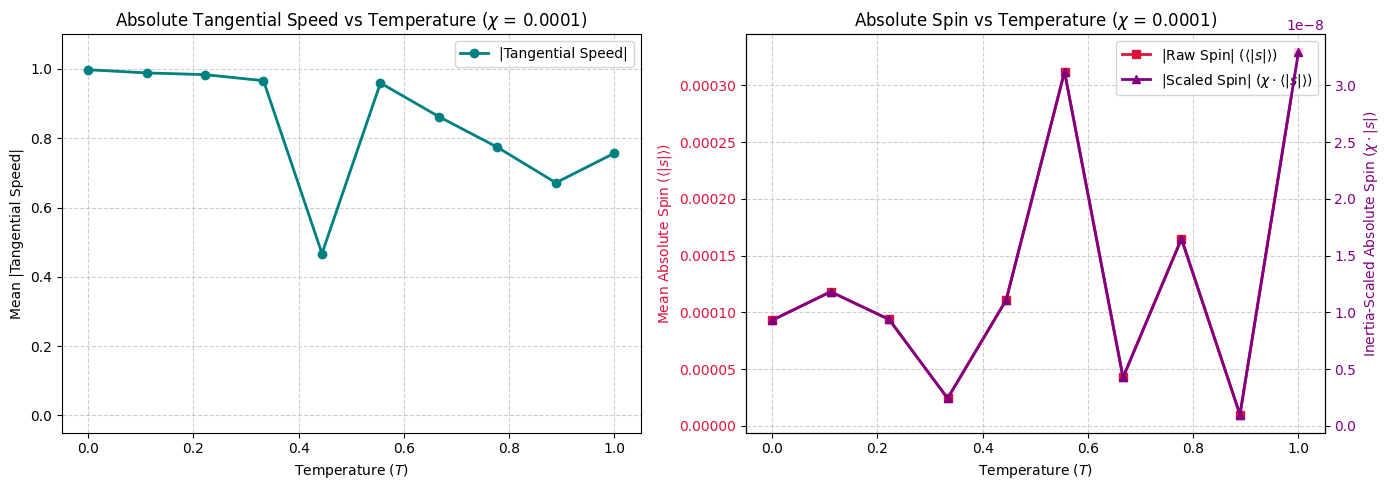

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_metrics_for_fixed_inertia(summary_df, target_inertia=None):
    """
    Plots the absolute magnitude of Tangential Speed and Spin (Raw & Inertia-Normalized) 
    vs Temperature for a specific fixed Inertia value, properly averaging over seeds.
    """
    if summary_df.empty:
        print("Error: summary_df is empty. Run the analysis cell first.")
        return

    # If no inertia is specified, pick the middle value from the available grid
    unique_inertias = sorted(summary_df['Inertia'].unique())
    if target_inertia is None:
        target_inertia = unique_inertias[len(unique_inertias) // 2]
    else:
        target_inertia = min(unique_inertias, key=lambda x: abs(x - target_inertia))
        
    print(f"Plotting absolute magnitudes for Fixed Inertia (chi) = {target_inertia}")
    
    # Filter for the target inertia
    df_fixed = summary_df[np.isclose(summary_df['Inertia'], target_inertia)].copy()
    
    # Take absolute value per run FIRST so clockwise/counter-clockwise don't cancel out across seeds
    if 'TangentialSpeed_mean' in df_fixed.columns:
        df_fixed['TangentialSpeed_mean'] = df_fixed['TangentialSpeed_mean'].abs()
        
    spin_col = 'SpinPerBird_mean' if 'SpinPerBird_mean' in df_fixed.columns else ('TotalSpin_mean' if 'TotalSpin_mean' in df_fixed.columns else None)
    if spin_col:
        df_fixed[spin_col] = df_fixed[spin_col].abs()

    # If multiple seeds exist per Temperature, group and average over their absolute values
    if 'RunID' in df_fixed.columns and df_fixed.duplicated(subset=['Temperature']).any():
        agg_dict = {}
        for col in df_fixed.columns:
            if col.endswith('_mean'):
                agg_dict[col] = ['mean', 'std']
            elif col.endswith('_var'):
                agg_dict[col] = ['mean'] # Average variance across seeds
                
        df_fixed = df_fixed.groupby('Temperature', as_index=False).agg(agg_dict)
        df_fixed.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in df_fixed.columns]
    
    df_fixed = df_fixed.sort_values('Temperature')
    temps = df_fixed['Temperature']
    
    # Setup figure with 2 subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # --- Subplot 1: Absolute Tangential Speed ---
    ts_mean_col = 'TangentialSpeed_mean_mean' if 'TangentialSpeed_mean_mean' in df_fixed.columns else 'TangentialSpeed_mean'
    ts_std_col = 'TangentialSpeed_mean_std' if 'TangentialSpeed_mean_std' in df_fixed.columns else None
    
    if ts_mean_col in df_fixed.columns:
        ts_mean = df_fixed[ts_mean_col]
        ts_std = df_fixed[ts_std_col] if ts_std_col and ts_std_col in df_fixed.columns else np.zeros_like(ts_mean)
        
        axes[0].plot(temps, ts_mean, 'o-', color='teal', lw=2, label='|Tangential Speed|')
        axes[0].fill_between(temps, np.clip(ts_mean - ts_std, 0, 1), ts_mean + ts_std, color='teal', alpha=0.2)
        axes[0].set_title(f'Absolute Tangential Speed vs Temperature ($\chi$ = {target_inertia:.4f})')
        axes[0].set_xlabel('Temperature ($T$)')
        axes[0].set_ylabel('Mean |Tangential Speed|')
        axes[0].set_ylim(-0.05, 1.1)
        axes[0].grid(True, linestyle='--', alpha=0.6)
        axes[0].legend()
    else:
        axes[0].text(0.5, 0.5, 'TangentialSpeed metric not found', ha='center', va='center')

    # --- Subplot 2: Absolute Spin & Normalized Spin ---
    spin_mean_col = f"{spin_col}_mean" if f"{spin_col}_mean" in df_fixed.columns else spin_col
    spin_std_col = f"{spin_col}_std" if f"{spin_col}_std" in df_fixed.columns else None
    
    if spin_mean_col in df_fixed.columns:
        spin_mean = df_fixed[spin_mean_col]
        spin_std = df_fixed[spin_std_col] if spin_std_col and spin_std_col in df_fixed.columns else np.zeros_like(spin_mean)
        
        # Raw Absolute Spin
        ax1 = axes[1]
        line1 = ax1.plot(temps, spin_mean, 's-', color='crimson', lw=2, label=r'|Raw Spin| ($\langle |s| \rangle$)')
        ax1.fill_between(temps, np.maximum(0, spin_mean - spin_std), spin_mean + spin_std, color='crimson', alpha=0.2)
        ax1.set_xlabel('Temperature ($T$)')
        ax1.set_ylabel(r'Mean Absolute Spin ($\langle |s| \rangle$)', color='crimson')
        ax1.tick_params(axis='y', labelcolor='crimson')
        ax1.grid(True, linestyle='--', alpha=0.6)
        
        # Inertia-Scaled Absolute Spin ($\chi \cdot |s|$)
        ax2 = ax1.twinx()
        scaled_spin = spin_mean * target_inertia
        line2 = ax2.plot(temps, scaled_spin, '^-', color='purple', lw=2, label=r'|Scaled Spin| ($\chi \cdot \langle |s| \rangle$)')
        ax2.set_ylabel(r'Inertia-Scaled Absolute Spin ($\chi \cdot |s|$)', color='purple')
        ax2.tick_params(axis='y', labelcolor='purple')
        
        # Combined legend
        lines = line1 + line2
        labels = [l.get_label() for l in lines]
        ax1.legend(lines, labels, loc='upper right')
        
        ax1.set_title(f'Absolute Spin vs Temperature ($\chi$ = {target_inertia:.4f})')
    else:
        axes[1].text(0.5, 0.5, 'Spin metric not found', ha='center', va='center')

    plt.tight_layout()
    plt.show()

# ==========================================
# EXECUTION
# ==========================================
CHOSEN_INERTIA = 0.001  # Pick middle inertia value automatically
plot_metrics_for_fixed_inertia(df_summary, target_inertia=CHOSEN_INERTIA)

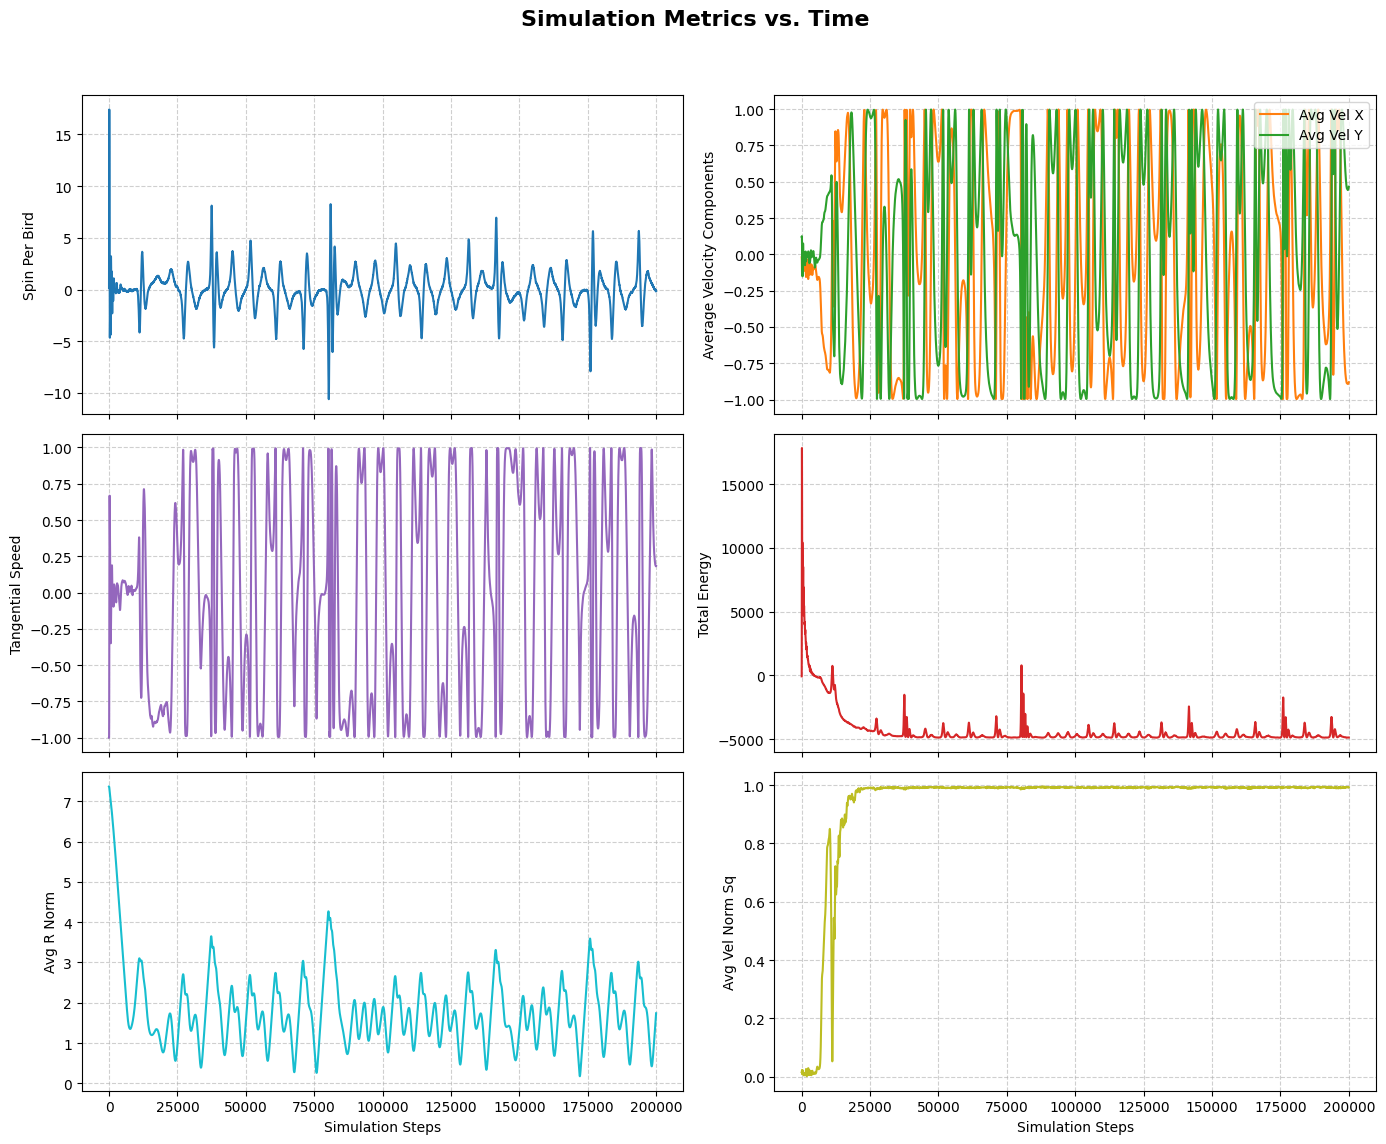

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Path to your simulation output folder and metrics file
output_folder = "output_test/run_017/"  # Change to your specific run folder if needed, e.g., "output/run_000"
metrics_file = f"{output_folder}/metrics.csv"

# Load the metrics data
df = pd.read_csv(metrics_file)

# Compute average velocity norm squared directly in pandas
df["AvgVelNormSq"] = (df["AvgVelX"] ** 2) + (df["AvgVelY"] ** 2)

# Set up a multi-panel figure (3 rows, 2 columns) to cleanly plot all metrics
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 12), sharex=True)
fig.suptitle("Simulation Metrics vs. Time", fontsize=16, fontweight="bold")

# 1. Spin Per Bird
axes[0, 0].plot(df["Step"], df["SpinPerBird"], color="tab:blue", lw=1.5)
axes[0, 0].set_ylabel("Spin Per Bird")
axes[0, 0].grid(True, linestyle="--", alpha=0.6)

# 2. Average Velocity Components
axes[0, 1].plot(
    df["Step"], df["AvgVelX"], label="Avg Vel X", color="tab:orange", lw=1.5
)
axes[0, 1].plot(
    df["Step"], df["AvgVelY"], label="Avg Vel Y", color="tab:green", lw=1.5
)
axes[0, 1].set_ylabel("Average Velocity Components")
axes[0, 1].legend(loc="upper right")
axes[0, 1].grid(True, linestyle="--", alpha=0.6)

# 3. Tangential Speed
axes[1, 0].plot(df["Step"], df["TangentialSpeed"], color="tab:purple", lw=1.5)
axes[1, 0].set_ylabel("Tangential Speed")
axes[1, 0].grid(True, linestyle="--", alpha=0.6)

# 4. Total Energy
axes[1, 1].plot(df["Step"], df["TotalEnergy"], color="tab:red", lw=1.5)
axes[1, 1].set_ylabel("Total Energy")
axes[1, 1].grid(True, linestyle="--", alpha=0.6)

# 5. Average Radius Norm (AvgRnorm) - loaded from sim
if "AvgRnorm" in df.columns:
    axes[2, 0].plot(df["Step"], df["AvgRnorm"], color="tab:cyan", lw=1.5)
    axes[2, 0].set_ylabel("Avg R Norm")
    axes[2, 0].grid(True, linestyle="--", alpha=0.6)
else:
    axes[2, 0].axis("off")
axes[2, 0].set_xlabel("Simulation Steps")

# 6. Average Velocity Norm Squared - computed in Python
axes[2, 1].plot(df["Step"], df["AvgVelNormSq"], color="tab:olive", lw=1.5)
axes[2, 1].set_ylabel("Avg Vel Norm Sq")
axes[2, 1].grid(True, linestyle="--", alpha=0.6)
axes[2, 1].set_xlabel("Simulation Steps")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()